# UAS Keamanan Data (DSF01) - Deteksi URL Phishing dengan Machine Learning

**Kelompok 4:** Jovanic Manuelo, Elvin Federic Aurelio, Agnes Aurelia

Notebook ini berisi seluruh alur pengolahan data dan pemodelan: pemeriksaan data, EDA, preprocessing, pembuatan fitur, pembagian data, pelatihan beberapa model, evaluasi, analisis kesalahan, dan penyimpanan model untuk aplikasi Flask.

| Hal | Keterangan |
|---|---|
| Ancaman | Phishing lewat URL (tautan palsu yang meniru situs resmi) |
| Masalah | Pengguna sulit membedakan tautan asli dan tautan phishing hanya dengan melihatnya |
| Pengguna sasaran | Pengguna internet umum, mahasiswa, staf admin yang menerima tautan lewat chat/email |
| Input aplikasi | Teks URL |
| Output aplikasi | Label (legitimate / phishing), probabilitas, alasan, dan saran tindakan |
| Kaitan dengan CIA | Terutama **kerahasiaan** (kredensial dan data pribadi dicuri). Akun yang diambil alih lalu mengancam **integritas** (data diubah, transaksi palsu) dan **ketersediaan** (pemilik terkunci dari akunnya) |

**Dataset:** Phishing URL dataset, Mendeley Data, DOI `10.17632/vfszbj9b36.1`, lisensi CC BY 4.0. https://data.mendeley.com/datasets/vfszbj9b36/1

## 1. Import dan konfigurasi

In [1]:
import json, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

# modul buatan sendiri (dipakai juga oleh aplikasi Flask)
from features import (normalize_url, registered_domain, extract_features,
                      URLFeatureExtractor, FEATURE_NAMES)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)

SEED = 42
DATA_DIR = "data/Phishing URL dataset"
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 2.3.3


## 2. Memuat dataset

Folder dataset berisi dua file:

- `URL dataset.csv` - data utama berlabel (legitimate dan phishing). **Dipakai untuk latih, validasi, dan uji.**
- `Phishing URLs.csv` - kumpulan URL phishing yang lebih baru, tanpa data legitimate. **Tidak ikut training**, hanya dipakai di bagian 11 sebagai uji eksternal.

In [2]:
df = pd.read_csv(f"{DATA_DIR}/URL dataset.csv")
ext_raw = pd.read_csv(f"{DATA_DIR}/Phishing URLs.csv")

print("Data utama     :", df.shape)
print("Data eksternal :", ext_raw.shape)
df.head()

Data utama     : (450176, 2)
Data eksternal : (54807, 2)


,url,type
0,https://www.google.com,legitimate
1,https://www.youtube.com,legitimate
2,https://www.facebook.com,legitimate
3,https://www.baidu.com,legitimate
4,https://www.wikipedia.org,legitimate


**Definisi label** (kolom `type`):

- `legitimate` - URL situs asli. Menurut halaman dataset, diambil dari daftar Majestic Million dan sumber lain.
- `phishing` - URL yang dilaporkan sebagai halaman phishing, bersumber dari PhishTank.

Untuk pemodelan, label diubah jadi angka: **phishing = 1 (kelas ancaman / positif)**, legitimate = 0.

,jumlah,persen
type,,
legitimate,345738,76.8
phishing,104438,23.2


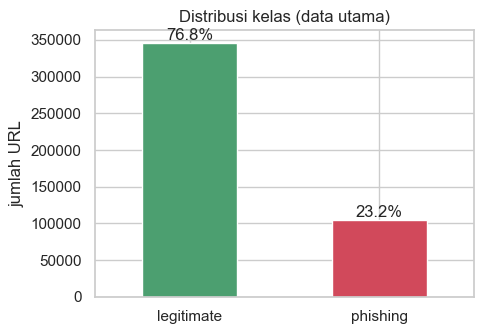

In [3]:
df["label"] = (df["type"] == "phishing").astype(int)

dist = df["type"].value_counts().to_frame("jumlah")
dist["persen"] = (dist["jumlah"] / len(df) * 100).round(2)
display(dist)

ax = dist["jumlah"].plot(kind="bar", color=["#4C9F70", "#D1495B"], figsize=(5, 3.5), rot=0)
ax.set_title("Distribusi kelas (data utama)"); ax.set_ylabel("jumlah URL"); ax.set_xlabel("")
for p, v in zip(ax.patches, dist["persen"]):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

Kelas tidak seimbang (sekitar 3 legitimate : 1 phishing). Konsekuensinya:

- accuracy saja menyesatkan, karena menebak "legitimate" terus sudah dapat ±77%;
- penyeimbangan kelas dilakukan lewat `class_weight="balanced"`, yang hanya berlaku saat model di-*fit* pada data latih.

## 3. Pemeriksaan kualitas data

In [4]:
print("Data kosong per kolom:"); print(df[["url", "type"]].isnull().sum().to_string())
print("\nBaris duplikat persis :", df.duplicated(subset=["url", "type"]).sum())
print("URL duplikat persis   :", df["url"].duplicated().sum())
print("\nPanjang URL (karakter):"); print(df["url"].str.len().describe().round(1).to_string())

Data kosong per kolom:
url     0
type    0

Baris duplikat persis : 0
URL duplikat persis   : 0

Panjang URL (karakter):
count    450176.0
mean         60.2
std          37.6
min           8.0
25%          40.0
50%          52.0
75%          71.0
max        2314.0


### Temuan EDA 1: skema dan `www` membocorkan label

Sebelum membuat fitur, kami cek awalan URL di tiap kelas.

In [5]:
chk = pd.DataFrame({
    "type": df["type"],
    "pakai_https": df["url"].str.lower().str.startswith("https://"),
    "pakai_www": df["url"].str.lower().str.contains(r"^[a-z]+://www\.", regex=True),
})
bias = (chk.groupby("type")[["pakai_https", "pakai_www"]].mean() * 100).round(2)
display(bias)

# "Model" satu aturan: kalau diawali https://www. -> legitimate, selain itu phishing
rule_pred = (~(chk["pakai_https"] & chk["pakai_www"])).astype(int)
print("Aturan satu baris 'bukan https://www. = phishing'")
print("  accuracy :", round(accuracy_score(df["label"], rule_pred), 4))
print("  precision:", round(precision_score(df["label"], rule_pred), 4))
print("  recall   :", round(recall_score(df["label"], rule_pred), 4))

,pakai_https,pakai_www
type,,
legitimate,99.99,99.80
phishing,6.21,13.04


Aturan satu baris 'bukan https://www. = phishing'
  accuracy : 0.9967
  precision: 0.9931
  recall   : 0.9926


Hampir semua URL legitimate ditulis `https://www.…`, sedangkan phishing tidak. Ini **artefak cara data dikumpulkan**, bukan ciri phishing: di dunia nyata banyak situs resmi tanpa `www`, dan banyak phishing yang sudah memakai HTTPS. Buktinya, aturan satu baris di atas sudah mendapat skor sangat tinggi tanpa belajar apa pun.

**Keputusan:** skema (`http://`, `https://`) dan `www.` dibuang dari semua URL sebelum fitur dibuat, baik saat training maupun di aplikasi. Skor akan turun, tapi model dipaksa belajar dari struktur domain dan path.

## 4. Preprocessing: normalisasi dan pembersihan

Fungsi `normalize_url` (di `features.py`) melakukan: buang skema, huruf kecil untuk host, buang `www.` di depan, buang `/` di ujung.

In [6]:
contoh = ["https://www.Google.com/", "http://paypal.com.secure-login.xyz/Account/Verify", "HTTP://192.168.0.1:8080/login.php?id=1"]
pd.DataFrame({"asli": contoh, "setelah normalisasi": [normalize_url(u) for u in contoh]})

,asli,setelah normalisasi
0,https://www.Google.com/,google.com
1,http://paypal.com.secure-login.xyz/Account/Verify,paypal.com.secure-login.xyz/Account/Verify
2,HTTP://192.168.0.1:8080/login.php?id=1,192.168.0.1:8080/login.php?id=1


In [7]:
df["url_norm"] = df["url"].map(normalize_url)

n_before = len(df)
dup_norm = df["url_norm"].duplicated().sum()
# URL yang sama tetapi labelnya bertentangan -> dibuang seluruhnya karena labelnya tidak bisa dipercaya
nun = df.groupby("url_norm")["label"].nunique()
konflik = set(nun[nun > 1].index)
print("URL kembar setelah normalisasi :", dup_norm)
print("URL dengan label bertentangan  :", len(konflik))

df = df[~df["url_norm"].isin(konflik)]
df = df.drop_duplicates(subset="url_norm", keep="first")
df = df[df["url_norm"].str.len() > 0].reset_index(drop=True)
print(f"Jumlah data: {n_before:,} -> {len(df):,}")
print(df["type"].value_counts().to_string())

URL kembar setelah normalisasi : 12346
URL dengan label bertentangan  : 3
Jumlah data: 450,176 -> 437,827
type
legitimate    345607
phishing       92220


Duplikat persis tidak ada, tetapi setelah dinormalisasi muncul ribuan URL kembar (hanya beda `http/https`, `www`, atau `/` di ujung). Kalau dibiarkan, URL yang pada dasarnya sama bisa masuk data latih dan data uji sekaligus, sehingga skor uji terlalu optimistis. Karena itu duplikat dihapus **sebelum** data dibagi.

In [8]:
print(registered_domain("https://www.google.com"))

google.com


### Temuan EDA 2: satu domain muncul berkali-kali

`registered_domain` mengambil domain utama, misalnya `en.wikipedia.org/wiki/…` menjadi `wikipedia.org`.

In [9]:
def safe_registered_domain(url, normalized_url):
    try:
        return registered_domain(url)
    except ValueError:
        # Keep malformed URLs grouped by their normalized host.
        host = str(normalized_url).split("/", 1)[0].strip().lower()
        return host or "invalid-url"

df["domain"] = [
    safe_registered_domain(url, normalized)
    for url, normalized in zip(df["url"], df["url_norm"])
]

print("Jumlah domain unik:", df["domain"].nunique(), "dari", len(df), "URL")
top = pd.concat({
    "legitimate": df[df.label == 0]["domain"].value_counts().head(8).rename_axis("domain").reset_index(name="jumlah"),
    "phishing": df[df.label == 1]["domain"].value_counts().head(8).rename_axis("domain").reset_index(name="jumlah"),
}, axis=1)
display(top)

per_dom = df.groupby("domain")["label"].nunique()
print("Domain yang punya URL di KEDUA kelas:", int((per_dom > 1).sum()))

Jumlah domain unik: 133768 dari 437827 URL


legitimate                  phishing       
          domain jumlah             domain jumlah
0  wikipedia.org  12895         google.com   1245
1    youtube.com   8627  000webhostapp.com    906
2   facebook.com   8274        mhcable.com    381
3   blogspot.com   7036          adnxs.com    255
4   linkedin.com   5016        wixsite.com    251
5     amazon.com   4722     sharepoint.com    223
6      yahoo.com   4228        twitter.com    217
7       imdb.com   3470            fc2.com    176

Domain yang punya URL di KEDUA kelas: 332


Ribuan URL berasal dari domain yang sama. Kalau data dibagi acak per baris, model bisa "menghafal" domain di data latih lalu bertemu domain yang sama di data uji.

**Keputusan:** pembagian data dilakukan **per domain** (`GroupShuffleSplit`), sehingga semua URL dari satu domain berada di satu bagian saja. Skor uji jadi mengukur kemampuan pada domain yang belum pernah dilihat.

Beberapa domain layanan umum (misalnya penyedia hosting atau penyimpanan file) muncul di kedua kelas. Artinya domain yang terkenal belum tentu aman, dan ini jadi salah satu sumber kesalahan model nanti.

## 5. Pembuatan fitur

Model tidak bisa membaca teks URL langsung, jadi setiap URL diubah menjadi 36 fitur numerik (fitur leksikal: dihitung dari teks URL saja, tanpa membuka halamannya). Ini aman karena URL berbahaya tidak pernah diakses.

| Kelompok | Fitur |
|---|---|
| Panjang | `url_length`, `host_length`, `path_length`, `query_length` |
| Host | `n_dots_host`, `n_subdomains`, `n_hyphens_host`, `n_digits_host`, `digit_ratio_host`, `longest_host_token`, `host_entropy`, `has_ip`, `has_port`, `is_shortener`, `is_common_tld`, `tld_length` |
| Path dan query | `path_depth`, `n_digits_path`, `n_hyphens_path`, `path_entropy`, `longest_path_token`, `has_double_slash`, `has_php`, `has_html`, `has_exe`, `n_query_params` |
| Karakter khusus | `n_underscores`, `n_percent`, `n_equals`, `n_ampersand`, `n_question`, `n_at`, `n_tilde`, `n_special_total` |
| Kata | `n_suspicious_words` (login, verify, secure, …), `brand_outside_domain` (nama merek muncul di subdomain/path padahal bukan domain merek itu) |

Ekstraksi fitur bersifat *stateless* (tidak mempelajari apa pun dari data), jadi aman dijalankan sebelum data dibagi.

In [13]:
t0 = time.time()
feature_rows = []
bad_indices = {}

for idx, url in df["url"].items():
    try:
        feature_rows.append(extract_features(url))
    except ValueError as e:
        
        bad_indices[idx] = str(e)

if bad_indices:
    print(f"Menghapus {len(bad_indices)} URL dengan format IPv6 tidak valid.")
    df = df.drop(index=bad_indices).reset_index(drop=True)

X_all = pd.DataFrame(feature_rows, columns=FEATURE_NAMES, index=df.index)
y_all = df["label"].values
print(f"Ekstraksi fitur selesai: {X_all.shape} dalam {time.time() - t0:.1f} detik")
print("Nilai kosong pada fitur:", int(X_all.isnull().sum().sum()))
X_all.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Menghapus 5 URL dengan format IPv6 tidak valid.
Ekstraksi fitur selesai: (437822, 36) dalam 76.0 detik
Nilai kosong pada fitur: 0


,mean,std,min,50%,max
url_length,48.96,37.92,4.0,41.00,2307.00
host_length,16.07,6.69,1.0,15.00,236.00
path_length,27.12,24.74,0.0,22.00,1897.00
query_length,5.58,28.48,0.0,0.00,2245.00
n_dots_host,1.33,0.59,0.0,1.00,20.00
n_subdomains,0.26,0.54,0.0,0.00,19.00
n_hyphens_host,0.08,0.37,0.0,0.00,21.00
n_digits_host,0.25,1.44,0.0,0.00,105.00
digit_ratio_host,0.02,0.08,0.0,0.00,0.82
longest_host_token,9.87,4.55,0.0,9.00,63.00


In [14]:
bad_indices

{382371: 'URL tidak memiliki hostname.',
 385292: 'URL tidak memiliki hostname.',
 393444: 'Format URL atau port tidak valid: Invalid IPv6 URL',
 394043: "Format URL atau port tidak valid: Port could not be cast to integer value as ' '",
 395231: 'URL tidak memiliki hostname.'}

In [15]:
rata = X_all.assign(label=y_all).groupby("label").mean().T
rata.columns = ["legitimate", "phishing"]
rata["rasio phishing/legit"] = (rata["phishing"] / rata["legitimate"].replace(0, np.nan)).round(2)
rata.round(3).sort_values("rasio phishing/legit", ascending=False)

,legitimate,phishing,rasio phishing/legit
has_exe,0.000,0.024,555.93
is_shortener,0.000,0.006,148.91
has_double_slash,0.000,0.004,119.25
n_suspicious_words,0.004,0.270,66.13
has_port,0.000,0.016,52.26
n_at,0.001,0.029,47.11
brand_outside_domain,0.003,0.071,23.66
n_digits_host,0.079,0.898,11.43
digit_ratio_host,0.006,0.053,9.15
has_php,0.045,0.255,5.70


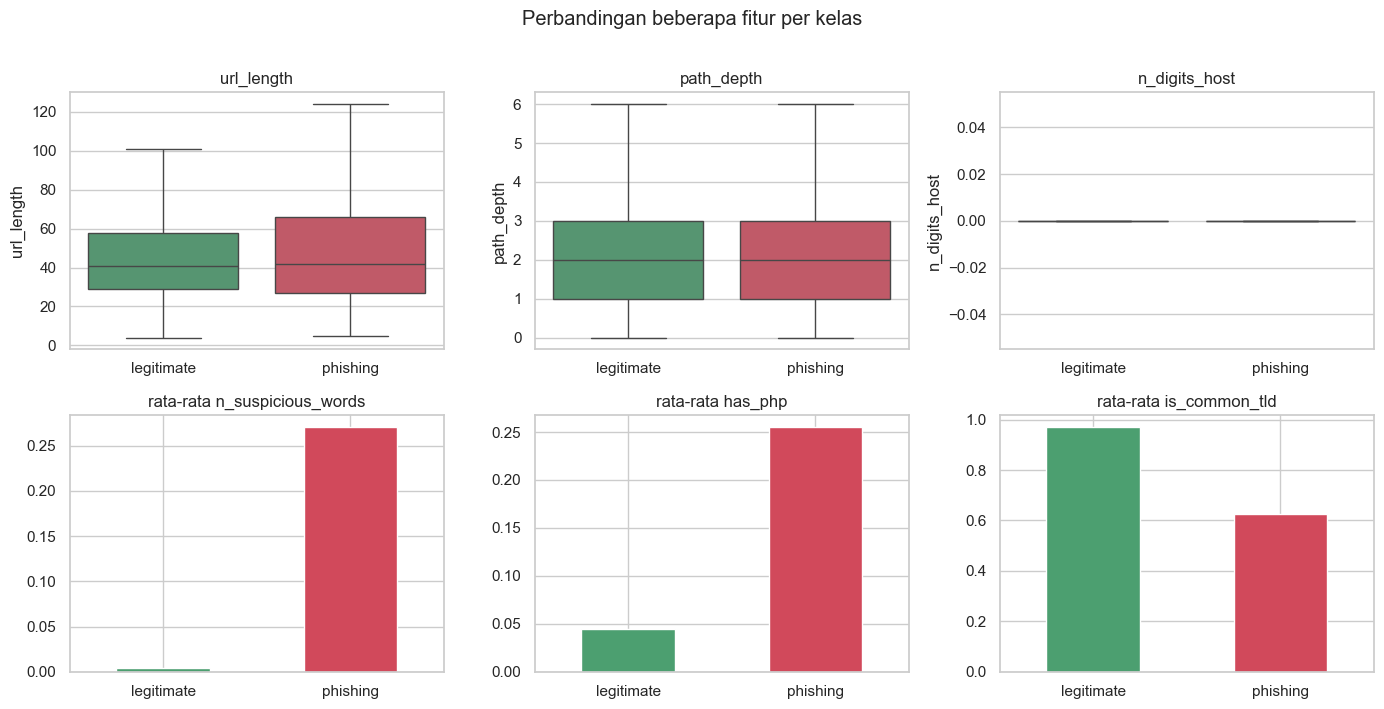

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
tmp = X_all.assign(kelas=np.where(y_all == 1, "phishing", "legitimate"))
pal = {"legitimate": "#4C9F70", "phishing": "#D1495B"}
for ax, col in zip(axes[0], ["url_length", "path_depth", "n_digits_host"]):
    sns.boxplot(data=tmp, x="kelas", y=col, ax=ax, palette=pal, showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
for ax, col in zip(axes[1], ["n_suspicious_words", "has_php", "is_common_tld"]):
    (tmp.groupby("kelas")[col].mean()).plot(kind="bar", ax=ax, color=[pal["legitimate"], pal["phishing"]], rot=0)
    ax.set_title(f"rata-rata {col}"); ax.set_xlabel("")
plt.suptitle("Perbandingan beberapa fitur per kelas", y=1.01); plt.tight_layout(); plt.show()

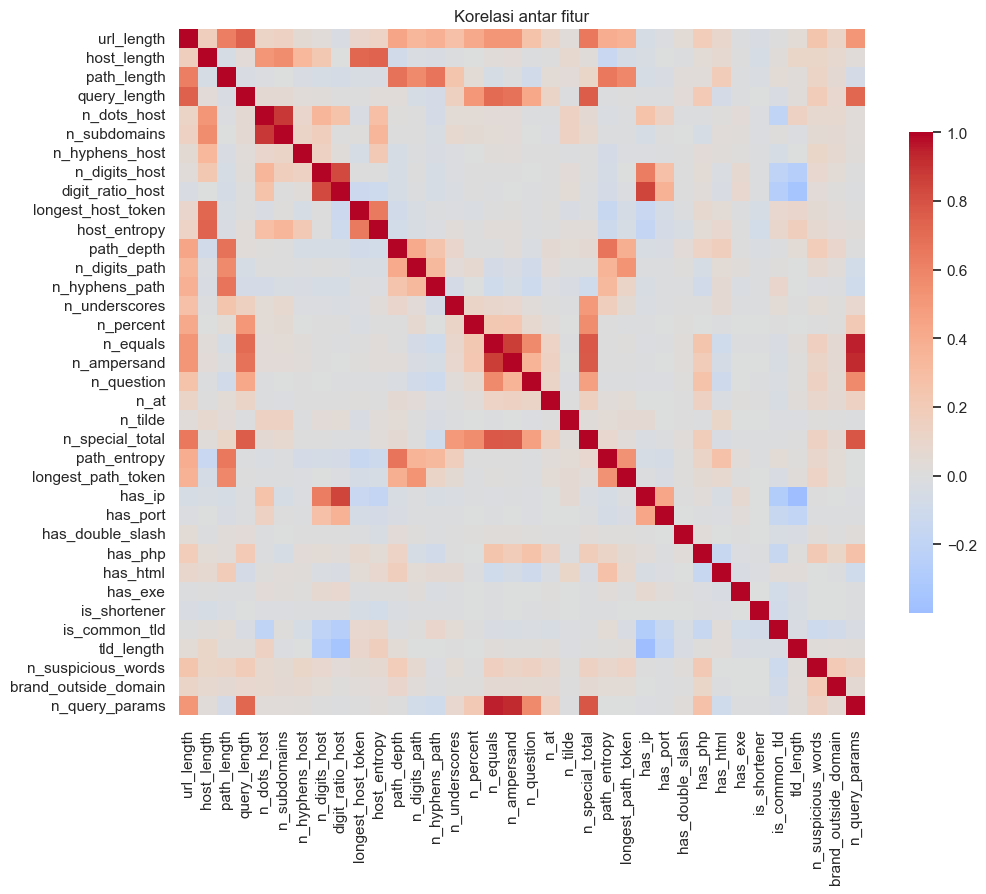

Pasangan fitur dengan korelasi > 0.85:
n_equals     n_query_params    0.95
n_ampersand  n_query_params    0.93
n_dots_host  n_subdomains      0.88
n_equals     n_ampersand       0.87


In [17]:
corr = X_all.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Korelasi antar fitur"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print("Pasangan fitur dengan korelasi > 0.85:"); print(pairs[pairs > 0.85].round(2).to_string())

**Temuan yang memengaruhi keputusan model:**

- URL phishing cenderung lebih panjang, punya lebih banyak angka di host, lebih sering memakai `.php`, alamat IP, dan kata seperti *login/verify*. URL legitimate lebih sering memakai TLD umum.
- Sebaran fitur sangat miring (banyak nol, ada nilai ekstrem) dan beberapa fitur saling berkorelasi tinggi. Model berbasis pohon tidak terganggu oleh skala maupun korelasi fitur, sehingga cocok. Logistic Regression tetap dicoba sebagai pembanding sederhana, dengan `StandardScaler`.
- Tidak ada fitur yang dibuang: jumlahnya hanya 36 dan model pohon bisa memilih sendiri fitur yang berguna.

## 6. Pembagian data: latih 70%, validasi 15%, uji 15% (per domain)

- **Latih**: untuk *fit* scaler dan model.
- **Validasi**: untuk membandingkan model dan memilih ambang keputusan.
- **Uji**: disimpan dan hanya dipakai sekali di evaluasi akhir.

In [18]:
groups = df["domain"].values
idx = np.arange(len(df))

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(idx, y_all, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
v, t = next(gss2.split(temp_idx, y_all[temp_idx], groups[temp_idx]))
val_idx, test_idx = temp_idx[v], temp_idx[t]

X_train, y_train = X_all.iloc[train_idx], y_all[train_idx]
X_val, y_val = X_all.iloc[val_idx], y_all[val_idx]
X_test, y_test = X_all.iloc[test_idx], y_all[test_idx]

d_tr, d_va, d_te = set(groups[train_idx]), set(groups[val_idx]), set(groups[test_idx])
print("Domain yang sama di latih & validasi:", len(d_tr & d_va))
print("Domain yang sama di latih & uji     :", len(d_tr & d_te))
print("Domain yang sama di validasi & uji  :", len(d_va & d_te))

pd.DataFrame({
    "bagian": ["latih", "validasi", "uji"],
    "jumlah URL": [len(train_idx), len(val_idx), len(test_idx)],
    "jumlah domain": [len(d_tr), len(d_va), len(d_te)],
    "% phishing": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
})

Domain yang sama di latih & validasi: 0
Domain yang sama di latih & uji     : 0
Domain yang sama di validasi & uji  : 0


,bagian,jumlah URL,jumlah domain,% phishing
0,latih,314857,93634,20.36
1,validasi,61140,20064,23.59
2,uji,61825,20065,22.16


## 7. Pelatihan dan perbandingan model

| Model | Alasan dicoba |
|---|---|
| Dummy (selalu menebak kelas terbanyak) | Batas bawah, untuk menunjukkan accuracy tinggi tidak selalu berarti model berguna |
| Logistic Regression | Sederhana, cepat, mudah dijelaskan. Butuh penskalaan fitur |
| Random Forest | Tahan terhadap fitur miring dan berkorelasi, menangkap hubungan non-linear |
| Hist Gradient Boosting | Biasanya paling akurat untuk data tabular, file model kecil, prediksi cepat |

Semua model memakai `class_weight="balanced"`. Bobot kelas dihitung dari data latih saja, begitu juga `StandardScaler` (berada di dalam `Pipeline`, jadi hanya di-*fit* pada data latih).

In [19]:
models = {
    "Dummy (kelas terbanyak)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=20, min_samples_leaf=3,
        class_weight="balanced", n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, class_weight="balanced", random_state=SEED),
}

def skor(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }

fitted, rows = {}, []
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train); dur = time.time() - t0
    fitted[name] = m
    rows.append({"model": name, **{f"val_{k}": v for k, v in skor(y_val, m.predict(X_val)).items()},
                 "train_f1": f1_score(y_train, m.predict(X_train), zero_division=0), "waktu_latih_detik": round(dur, 1)})
    print(f"{name:<26} selesai dalam {dur:.1f} detik")

hasil_val = pd.DataFrame(rows).set_index("model").round(4)
hasil_val

Dummy (kelas terbanyak)    selesai dalam 0.0 detik
Logistic Regression        selesai dalam 1.8 detik
Random Forest              selesai dalam 17.2 detik
Hist Gradient Boosting     selesai dalam 9.6 detik


,val_accuracy,val_precision,val_recall,val_f1,train_f1,waktu_latih_detik
model,,,,,,
Dummy (kelas terbanyak),0.7641,0.0000,0.0000,0.0000,0.0000,0.0
Logistic Regression,0.8312,0.6254,0.7090,0.6645,0.7157,1.8
Random Forest,0.8788,0.7169,0.8033,0.7576,0.8654,17.2
Hist Gradient Boosting,0.8745,0.6957,0.8316,0.7576,0.8432,9.6


Precision, recall, dan F1 dihitung untuk **kelas phishing**. Kolom `train_f1` dibandingkan dengan `val_f1` untuk melihat overfitting: selisih yang besar berarti model terlalu menghafal data latih.

Model dipilih berdasarkan **F1 pada data validasi**, karena F1 menyeimbangkan precision (tidak asal menuduh situs asli) dan recall (tidak meloloskan phishing).

In [20]:
best_name = hasil_val.drop(index="Dummy (kelas terbanyak)")["val_f1"].idxmax()
best_model = fitted[best_name]
print("Model terpilih:", best_name)

Model terpilih: Random Forest


### Memilih ambang keputusan (threshold) pada data validasi

Model mengeluarkan probabilitas phishing. Secara bawaan, ≥ 0,5 dianggap phishing. Ambang lebih rendah menangkap lebih banyak phishing (recall naik) tetapi lebih sering salah menuduh situs asli (precision turun).

,threshold,accuracy,precision,recall,f1
0,0.20,0.6569,0.3998,0.9065,0.5549
1,0.25,0.7121,0.4449,0.8906,0.5934
2,0.30,0.7618,0.4972,0.8752,0.6342
3,0.35,0.8025,0.5524,0.8580,0.6721
4,0.40,0.8323,0.6034,0.8425,0.7032
5,0.45,0.8614,0.6671,0.8235,0.7371
6,0.50,0.8788,0.7169,0.8033,0.7576
7,0.55,0.8910,0.7614,0.7830,0.7721
8,0.60,0.8955,0.7898,0.7587,0.7739
9,0.65,0.8977,0.8136,0.7347,0.7721


Threshold dengan F1 validasi tertinggi: 0.6


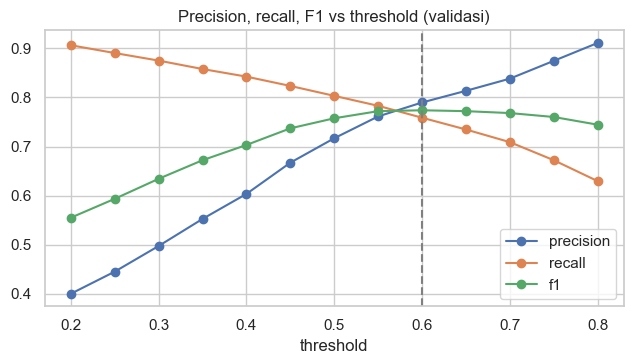

In [21]:
p_val = best_model.predict_proba(X_val)[:, 1]
th_rows = []
for th in np.arange(0.20, 0.81, 0.05):
    pred = (p_val >= th).astype(int)
    th_rows.append({"threshold": round(th, 2), **skor(y_val, pred)})
th_df = pd.DataFrame(th_rows).round(4)
display(th_df)

THRESHOLD = float(th_df.loc[th_df["f1"].idxmax(), "threshold"])
print("Threshold dengan F1 validasi tertinggi:", THRESHOLD)

ax = th_df.plot(x="threshold", y=["precision", "recall", "f1"], marker="o", figsize=(6.5, 3.8))
ax.axvline(THRESHOLD, color="gray", ls="--"); ax.set_title("Precision, recall, F1 vs threshold (validasi)")
plt.tight_layout(); plt.show()

## 8. Evaluasi akhir pada data uji

Data uji baru dipakai di sini, satu kali, dengan model dan threshold yang sudah ditetapkan dari data validasi.

Model: Random Forest | threshold: 0.6

              precision    recall  f1-score   support

  legitimate     0.9495    0.9504    0.9499     48124
    phishing     0.8251    0.8224    0.8238     13701

    accuracy                         0.9220     61825
   macro avg     0.8873    0.8864    0.8869     61825
weighted avg     0.9219    0.9220    0.9220     61825

TN=45,736  FP=2,388  FN=2,433  TP=11,268


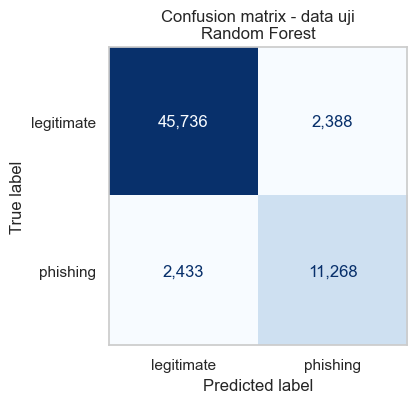

In [22]:
p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)

test_scores = skor(y_test, pred_test)
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()

print(f"Model: {best_name} | threshold: {THRESHOLD}\n")
print(classification_report(y_test, pred_test, target_names=["legitimate", "phishing"], digits=4))
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["legitimate", "phishing"]).plot(ax=ax, cmap="Blues", values_format=",d", colorbar=False)
ax.set_title(f"Confusion matrix - data uji\n{best_name}"); ax.grid(False)
plt.tight_layout(); plt.savefig("static/confusion_matrix.png", dpi=130); plt.show()

In [23]:
# Semua model pada data uji (hanya untuk dilaporkan; pemilihan model tetap dari validasi)
rows = []
for name, m in fitted.items():
    pr = (m.predict_proba(X_test)[:, 1] >= (THRESHOLD if name == best_name else 0.5)).astype(int)
    rows.append({"model": name, **skor(y_test, pr)})
hasil_test = pd.DataFrame(rows).set_index("model").round(4)
hasil_test

,accuracy,precision,recall,f1
model,,,,
Dummy (kelas terbanyak),0.7784,0.0000,0.0000,0.0000
Logistic Regression,0.8415,0.6149,0.7615,0.6804
Random Forest,0.9220,0.8251,0.8224,0.8238
Hist Gradient Boosting,0.9103,0.7541,0.8830,0.8135


**Cara membaca hasil (kelas ancaman = phishing):**

- **False Negative (FN)** - phishing diprediksi aman. Ini kesalahan paling berbahaya: pengguna merasa yakin lalu memasukkan kata sandi atau data kartu, sehingga kerahasiaan data bocor.
- **False Positive (FP)** - situs asli dituduh phishing. Dampaknya gangguan dan turunnya kepercayaan pada aplikasi; kalau terlalu sering, pengguna akan mengabaikan peringatan.

Karena FN lebih mahal, aplikasi tidak pernah menampilkan "pasti aman": hasil legitimate tetap disertai saran untuk memeriksa alamat domain.

## 9. Analisis kesalahan prediksi

In [24]:
test_df = df.iloc[test_idx][["url", "url_norm", "domain", "type"]].copy()
test_df["prob_phishing"] = p_test.round(3)
test_df["prediksi"] = np.where(pred_test == 1, "phishing", "legitimate")

fn_df = test_df[(y_test == 1) & (pred_test == 0)].sort_values("prob_phishing")
fp_df = test_df[(y_test == 0) & (pred_test == 1)].sort_values("prob_phishing", ascending=False)

print("Contoh FALSE NEGATIVE (phishing yang lolos):")
display(fn_df[["url", "prob_phishing"]].head(8))
print("Contoh FALSE POSITIVE (situs asli yang dituduh phishing):")
display(fp_df[["url", "prob_phishing"]].head(8))

Contoh FALSE NEGATIVE (phishing yang lolos):


,url,prob_phishing
379543,http://bankinnovation.net/2016/01/wells-fargo-to-roll-out-biometric-logins-by-june/,0.017
409448,http://www.hanssamios.com/wordpress/2015/08/27/improving-stories-with-given-when-then-...,0.020
417402,http://sitrox.tripod.com/germa-gmx/index/merci-20162.html,0.020
417403,http://sitrox.tripod.com/germa-gmx/index/vb-20162.html,0.021
384920,http://aijcs.blogspot.com/2005/03/colourful-life-of-aij.html,0.022
367006,http://zolfah.org/redirect-usaa-online-reference/comm.htm,0.022
351732,http://safety.amw.com/family/ask-john-walsh-how-can-i-tell-if-a-child-has-been-abused/,0.023
351733,http://safety.amw.com/home/stop-domestic-violence-before-it-starts/,0.025


Contoh FALSE POSITIVE (situs asli yang dituduh phishing):


,url,prob_phishing
70751,https://www.me.lt/3KUFX,0.998
225681,https://www.justin.tv/peppas92,0.995
289857,https://www.simpleplan.cz/en/index.php/band/members/jeff-stinco/,0.995
106936,https://www.tmi.me/hsbhj,0.993
106935,https://www.tmi.me/hJKsv,0.993
245586,https://www.medkonsult.sk/contact.php,0.992
154644,https://www.bromleyfc.tv/season1011/,0.991
182464,https://www.evertoncollection.org.uk/players,0.990


In [25]:
# Kesalahan berdasarkan bentuk URL: hanya domain (tanpa path) vs punya path
bentuk = np.where(X_test["path_length"].values + X_test["query_length"].values == 0, "hanya domain", "ada path/query")
err = pd.DataFrame({"bentuk": bentuk, "y": y_test, "pred": pred_test})
ring = err.groupby("bentuk").apply(lambda g: pd.Series({
    "jumlah": len(g),
    "phishing_asli": int(g.y.sum()),
    "recall_phishing": round(recall_score(g.y, g.pred, zero_division=0), 4),
    "precision_phishing": round(precision_score(g.y, g.pred, zero_division=0), 4),
    "FN": int(((g.y == 1) & (g.pred == 0)).sum()),
    "FP": int(((g.y == 0) & (g.pred == 1)).sum()),
}))
display(ring)

print("Rata-rata fitur: FN vs phishing yang tertangkap (TP)")
m_fn = X_test[(y_test == 1) & (pred_test == 0)].mean()
m_tp = X_test[(y_test == 1) & (pred_test == 1)].mean()
cmp = pd.DataFrame({"FN (lolos)": m_fn, "TP (tertangkap)": m_tp}).round(3)
display(cmp.loc[["url_length", "path_depth", "n_digits_host", "n_suspicious_words", "has_php", "is_common_tld", "n_subdomains", "longest_path_token"]])

,jumlah,phishing_asli,recall_phishing,precision_phishing,FN,FP
bentuk,,,,,,
ada path/query,50642.0,12521.0,0.8443,0.8454,1950.0,1933.0
hanya domain,11183.0,1180.0,0.5907,0.6050,483.0,455.0


Rata-rata fitur: FN vs phishing yang tertangkap (TP)


,FN (lolos),TP (tertangkap)
url_length,43.229,72.888
path_depth,1.870,2.525
n_digits_host,0.106,1.213
n_suspicious_words,0.006,0.289
has_php,0.053,0.288
is_common_tld,0.945,0.558
n_subdomains,0.296,0.281
longest_path_token,6.328,10.536


**Pola kesalahan:**

- **FN** umumnya URL berlabel phishing yang bentuknya seperti halaman artikel atau blog biasa: domain `.com`, path deskriptif dengan tanda hubung, tanpa kata mencurigakan. Kemungkinannya dua: situs asli yang diretas lalu dipakai untuk phishing, atau label di dataset sumber yang kurang tepat (*label noise*). Kami tidak membuka URL-nya sehingga tidak bisa memastikan. Yang jelas, dari teks URL saja keduanya tidak bisa dibedakan dari situs normal.
- **FP** umumnya situs asli dengan TLD negara yang jarang muncul di data (`.no`, `.ro`, `.sk`), halaman `.php`, atau tautan pendek berisi kode acak. Model sangat bergantung pada fitur `is_common_tld`, sehingga cenderung curiga pada situs kecil dengan TLD yang tidak umum.
- Halaman login resmi (URL mengandung `login`, `signin`, `account`) juga berisiko jadi FP, karena data legitimate jarang berisi halaman login sementara data phishing penuh dengan kata itu.
- URL yang **hanya berupa domain** jauh lebih sulit (lihat tabel: recall dan precision-nya paling rendah), karena tidak ada path yang bisa dianalisis.

## 10. Fitur yang paling berpengaruh

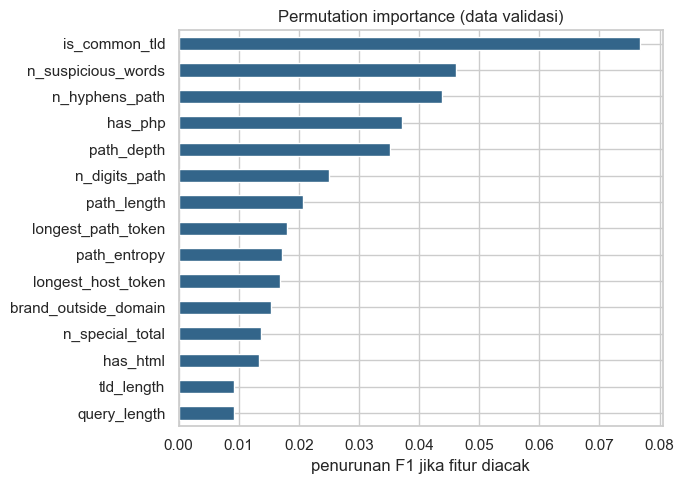

is_common_tld           0.0767
n_suspicious_words      0.0462
n_hyphens_path          0.0439
has_php                 0.0372
path_depth              0.0352
n_digits_path           0.0251
path_length             0.0208
longest_path_token      0.0180
path_entropy            0.0172
longest_host_token      0.0169
brand_outside_domain    0.0154
n_special_total         0.0138
has_html                0.0134
tld_length              0.0093
query_length            0.0092
dtype: float64

In [27]:
rng = np.random.RandomState(SEED)
sub = rng.choice(len(X_val), size=min(20000, len(X_val)), replace=False)
pi = permutation_importance(best_model, X_val.iloc[sub], y_val[sub], scoring="f1", n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_NAMES).sort_values(ascending=False)

ax = imp.head(15).sort_values().plot(kind="barh", figsize=(7, 5), color="#33658A")
ax.set_title("Permutation importance (data validasi)"); ax.set_xlabel("penurunan F1 jika fitur diacak")
plt.tight_layout(); plt.savefig("static/feature_importance.png", dpi=130); plt.show()
imp.head(15).round(4)

Permutation importance mengukur seberapa jauh F1 turun kalau nilai satu fitur diacak. Makin besar penurunannya, makin model bergantung pada fitur itu. Dihitung pada data validasi, bukan data uji.

## 11. Uji eksternal: `Phishing URLs.csv`

File ini berisi URL phishing yang lebih baru dan tidak pernah dilihat model. Karena semuanya phishing, metrik yang bisa dihitung hanya **recall** (berapa persen yang tertangkap). Precision tidak bisa dihitung karena tidak ada URL legitimate.

In [28]:
ext = ext_raw.copy()
ext["url_norm"] = ext["url"].map(normalize_url)
ext = ext.drop_duplicates("url_norm")
ext = ext[~ext["url_norm"].isin(set(df["url_norm"]))].reset_index(drop=True)   # buang yang sudah ada di data utama
ext["domain"] = ext["url"].map(registered_domain)

X_ext = URLFeatureExtractor().transform(ext["url"])
p_ext = best_model.predict_proba(X_ext)[:, 1]
ext["pred"] = (p_ext >= THRESHOLD).astype(int)
ext["domain_pernah_dilatih"] = ext["domain"].isin(d_tr)

ext_recall = ext["pred"].mean()
print(f"Jumlah URL eksternal (setelah dibersihkan): {len(ext):,}")
print(f"Recall keseluruhan                        : {ext_recall:.4f}")
display(ext.groupby("domain_pernah_dilatih")["pred"].agg(jumlah="size", recall="mean").round(4))

per_host = ext.groupby("domain")["pred"].agg(jumlah="size", recall="mean").sort_values("jumlah", ascending=False).head(12).round(3)
per_host

Jumlah URL eksternal (setelah dibersihkan): 51,273
Recall keseluruhan                        : 0.7977


,jumlah,recall
domain_pernah_dilatih,,
False,43667,0.8571
True,7606,0.4566


,jumlah,recall
domain,,
google.com,4014,0.756
cf-ipfs.com,3503,0.978
weeblysite.com,3332,0.968
cloudflare-ipfs.com,2890,0.997
r2.dev,2367,1.000
web.app,2107,0.998
firebaseapp.com,2084,0.372
aragon.network,1867,1.000
pages.dev,1792,0.999


**Pembacaan hasil:**

- Recall keseluruhan sedikit di bawah recall pada data uji, jadi model masih cukup berguna untuk phishing yang lebih baru.
- Namun hasilnya sangat tidak merata. Phishing di gateway IPFS atau `r2.dev` hampir semuanya tertangkap (URL-nya panjang dan acak), sedangkan phishing yang menumpang di layanan sah seperti `adobe.com`, `weebly.com`, dan `firebaseapp.com` banyak yang lolos, karena bentuk URL-nya sama dengan pemakaian normal layanan tersebut.
- Pada domain yang juga muncul di data latih, recall turun tajam. Di data latih, domain-domain itu kebanyakan berisi URL legitimate, sehingga pola URL-nya dipelajari sebagai "aman".

Ini keterbatasan penting: skor pada data uji tidak menjamin kinerja yang sama pada phishing model baru. Model perlu dilatih ulang secara berkala dengan data terbaru, dan untuk phishing di layanan sah dibutuhkan informasi di luar teks URL (isi halaman, reputasi).

## 12. Menyimpan model beserta preprocessing

Yang disimpan adalah satu `Pipeline` berisi **ekstraksi fitur + model** (scaler ikut di dalamnya kalau model terpilih memakainya). Dengan begitu aplikasi cukup memanggil `pipeline.predict_proba(["url mentah"])` dan preprocessing-nya dijamin sama dengan saat training.

In [29]:
final_pipeline = Pipeline([
    ("features", URLFeatureExtractor()),   # normalisasi + 36 fitur
    ("model", best_model),                 # sudah dilatih pada data latih
])

# Pastikan pipeline dari URL mentah memberi hasil yang sama dengan evaluasi di atas
cek = final_pipeline.predict_proba(df.iloc[test_idx]["url"].head(2000))[:, 1]
assert np.allclose(cek, p_test[:2000]), "Hasil pipeline berbeda dengan evaluasi!"

joblib.dump(final_pipeline, "model/phishing_url_pipeline.joblib", compress=3)

metadata = {
    "model_name": best_name,
    "threshold": THRESHOLD,
    "trained_at": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "sklearn_version": sklearn.__version__,
    "feature_names": FEATURE_NAMES,
    "dataset": {"name": "Phishing URL dataset (Mendeley Data)", "doi": "10.17632/vfszbj9b36.1",
                "url": "https://data.mendeley.com/datasets/vfszbj9b36/1",
                "n_raw": int(n_before), "n_clean": int(len(df)),
                "n_legitimate": int((y_all == 0).sum()), "n_phishing": int((y_all == 1).sum())},
    "split": {"train": int(len(train_idx)), "val": int(len(val_idx)), "test": int(len(test_idx)), "method": "GroupShuffleSplit per domain (70/15/15)"},
    "test_metrics": {k: round(float(v), 4) for k, v in test_scores.items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "validation_comparison": hasil_val.reset_index().to_dict(orient="records"),
    "test_comparison": hasil_test.reset_index().to_dict(orient="records"),
    "external_test": {"n": int(len(ext)), "recall": round(float(ext_recall), 4)},
    "top_features": imp.head(10).round(4).to_dict(),
}
with open("model/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

import os
print("Tersimpan: model/phishing_url_pipeline.joblib (%.1f MB)" % (os.path.getsize("model/phishing_url_pipeline.joblib") / 1e6))
print("Tersimpan: model/metadata.json")

Tersimpan: model/phishing_url_pipeline.joblib (27.0 MB)
Tersimpan: model/metadata.json


In [30]:
# Uji muat ulang: sama seperti yang dilakukan aplikasi Flask
loaded = joblib.load("model/phishing_url_pipeline.joblib")
coba = [
    "https://www.wikipedia.org/",
    "wikipedia.org",                         # tanpa skema & www -> harus sama dengan baris di atas
    "https://github.com/scikit-learn/scikit-learn",
    "http://paypal.com.secure-login-update.xyz/webscr/verify/account.php?id=8821",
    "http://192.168.10.5/bank/login.php",
]
pr = loaded.predict_proba(coba)[:, 1]
pd.DataFrame({"url": coba, "prob_phishing": pr.round(3), "prediksi": np.where(pr >= THRESHOLD, "phishing", "legitimate")})

,url,prob_phishing,prediksi
0,https://www.wikipedia.org/,0.190,legitimate
1,wikipedia.org,0.190,legitimate
2,https://github.com/scikit-learn/scikit-learn,0.022,legitimate
3,http://paypal.com.secure-login-update.xyz/webscr/verify/account.php?id=8821,0.953,phishing
4,http://192.168.10.5/bank/login.php,1.000,phishing


## 13. Ringkasan dan keterbatasan

**Ringkasan alur**

1. Data utama 450.176 URL diperiksa: tidak ada nilai kosong, tetapi ada bias awalan `https://www.` dan ribuan URL kembar setelah dinormalisasi.
2. Skema dan `www` dibuang, duplikat dihapus, lalu 36 fitur leksikal dibuat dari teks URL.
3. Data dibagi 70/15/15 per domain agar domain yang sama tidak bocor antar bagian.
4. Empat model dibandingkan pada data validasi, model terbaik dipilih dari F1, threshold dipilih dari validasi, lalu dievaluasi sekali pada data uji.
5. Model diuji lagi pada kumpulan phishing eksternal yang lebih baru.
6. Pipeline (fitur + model) disimpan ke `model/phishing_url_pipeline.joblib` untuk aplikasi Flask.

**Keterbatasan model**

- Hanya melihat **teks URL**. Isi halaman, sertifikat, umur domain, dan reputasi tidak diperiksa, jadi situs asli yang diretas atau phishing yang menumpang di layanan sah sulit dikenali.
- URL yang hanya berupa domain memberi sedikit informasi sehingga prediksinya kurang pasti.
- Data legitimate berasal dari daftar situs populer, sehingga situs kecil atau lokal yang sah bisa terlihat "asing" bagi model.
- Pola phishing berubah terus (terlihat dari turunnya recall pada data eksternal), sehingga model perlu dilatih ulang secara berkala.
- Hasil model adalah alat bantu, bukan keputusan akhir. Aplikasi selalu menyertakan saran tindakan.

**Sumber**

- Dataset: Phishing URL dataset, Mendeley Data, DOI 10.17632/vfszbj9b36.1 (CC BY 4.0).
- Pustaka: pandas, NumPy, scikit-learn, matplotlib, seaborn, joblib, tldextract, Flask.
- Bantuan AI: penyusunan kode notebook dan aplikasi dibantu asisten AI (Claude, Anthropic). Seluruh hasil diperiksa dan dipahami oleh anggota kelompok.